# 📔 **Resolución**
Una vez que la nota sea entregada, encontrarás la resolución en este link de notion:

https://www.notion.so/R-DT-and-ensemble-models-1eb05737435780bf924fd27f0fc8c06c?source=copy_link

Recuerda que existen varias formar de solucionar las actividades propuestas en los laboratorios. Toma la resolución entregada como referencia. En caso de que el link de resolución no esté público, solicita acceso en el mismo link de notion.|

# Decision Trees, Random Forest and XGBoost models

Let's import the libraries you will use.

In [1]:
!wget https://raw.githubusercontent.com/mtgca/datasets_public/main/deeplearning.mplstyle
!wget https://raw.githubusercontent.com/mtgca/datasets_public/main/heart.csv


--2026-11-22 20:40:00--  https://raw.githubusercontent.com/mtgca/datasets_public/main/deeplearning.mplstyle
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.111.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 5013 (4.9K) [text/plain]
Saving to: ‘deeplearning.mplstyle’

deeplearning.mplsty 100%[===================>]   4.90K  --.-KB/s    in 0s      

2026-11-22 20:40:00 (55.0 MB/s) - ‘deeplearning.mplstyle’ saved [5013/5013]

--2026-11-22 20:40:00--  https://raw.githubusercontent.com/mtgca/datasets_public/main/heart.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 35921 (35K) [text

In [2]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
!pip install xgboost --quiet
import xgboost
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
plt.style.use('./deeplearning.mplstyle')

RANDOM_STATE = 55 ## You will pass it to every sklearn call so we ensure reproducibility

# 1. Loading the Dataset

From [Kaggle](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction)

Context
Cardiovascular diseases (CVDs) are the number 1 cause of death globally, taking an estimated 17.9 million lives each year, which accounts for 31% of all deaths worldwide. Heart failure is a common event caused by CVDs and this dataset contains 11 features that can be used to predict a possible heart disease.

People with cardiovascular disease or who are at high cardiovascular risk need early detection and management wherein a machine learning model can be of great help.

You will develop models to predict how likely a particular person is in developint cardiovascular disease, given all the information below.

#### Attribute Information
- Age: age of the patient [years]
- Sex: sex of the patient [M: Male, F: Female]
- ChestPainType: chest pain type [TA: Typical Angina, ATA: Atypical Angina, NAP: Non-Anginal Pain, ASY: Asymptomatic]
- RestingBP: resting blood pressure [mm Hg]
- Cholesterol: serum cholesterol [mm/dl]
- FastingBS: fasting blood sugar [1: if FastingBS > 120 mg/dl, 0: otherwise]
- RestingECG: resting electrocardiogram results [Normal: Normal, ST: having ST-T wave abnormality (T wave inversions and/or ST elevation or depression of > 0.05 mV), LVH: showing probable or definite left ventricular hypertrophy by Estes' criteria]
- MaxHR: maximum heart rate achieved [Numeric value between 60 and 202]
- ExerciseAngina: exercise-induced angina [Y: Yes, N: No]
- Oldpeak: oldpeak = ST [Numeric value measured in depression]
- ST_Slope: the slope of the peak exercise ST segment [Up: upsloping, Flat: flat, Down: downsloping]
- HeartDisease: output class [1: heart disease, 0: Normal]

Let's now load the dataset. As you can see above, the variables:

- Sex
- ChestPainType
- RestingECG
- ExerciseAngina
- ST_Slope

Are *categorical*, so you must one-hot encode them.

In [3]:
# Load the dataset using pandas
df = pd.read_csv("heart.csv")

In [4]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


You must perform some data engineering before working with the models. There are 5 categorical features, so you will use Pandas to one-hot encode them.

## 2. One-hot encoding using Pandas

First you will remove the binary variables, because one-hot encoding them would do nothing to them. To achieve this you will just count how many different values there are in each categorical variable and consider only the variables with 3 or more values.

In [5]:
cat_variables = ['Sex',
'ChestPainType',
'RestingECG',
'ExerciseAngina',
'ST_Slope'
]

As a reminder, one-hot encoding aims to transform a categorical variable with `n` outputs into `n` binary variables.

Pandas has a built-in method to one-hot encode variables, it is the function `pd.get_dummies`. There are several arguments to this function, but here you will use only a few. They are:

 - data: DataFrame to be used
 - prefix: A list with prefixes, so you know which value you are dealing with
 - columns: the list of columns that will be one-hot encoded. 'prefix' and 'columns' must have the same length.

For more information, you can always type `help(pd.get_dummies)` to read the function's full documentation.

In [6]:
# This will replace the columns with the one-hot encoded ones and keep the columns outside 'columns' argument as it is.
df = pd.get_dummies(data = df,
                         prefix = cat_variables,
                         columns = cat_variables)

In [7]:
df.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_F,Sex_M,ChestPainType_ASY,...,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ExerciseAngina_N,ExerciseAngina_Y,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0.0,0,False,True,False,...,False,False,False,True,False,True,False,False,False,True
1,49,160,180,0,156,1.0,1,True,False,False,...,True,False,False,True,False,True,False,False,True,False
2,37,130,283,0,98,0.0,0,False,True,False,...,False,False,False,False,True,True,False,False,False,True
3,48,138,214,0,108,1.5,1,True,False,True,...,False,False,False,True,False,False,True,False,True,False
4,54,150,195,0,122,0.0,0,False,True,False,...,True,False,False,True,False,True,False,False,False,True


You now will define the final set of variables that will be used by the models you will build in this lab.

In [8]:
var = [x for x in df.columns if x not in 'HeartDisease'] ## Removing our target variable

Note how the number of variables has changed. You started with 11 variables now you have:

In [9]:
print(len(var))

20


# 3. Splitting the Dataset

In this section, you will split our dataset into train and test datasets. You will use the function `train_test_split` from Scikit-learn. Let's just check its arguments.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(df[var], df['HeartDisease'], train_size = 0.8, random_state = RANDOM_STATE)

# We will keep the shuffle = True since our dataset has not any time dependency.

In [11]:
print(f'train samples: {len(X_train)}\ntest samples: {len(X_test)}')
print(f'target proportion: {sum(y_train)/len(y_train):.4f}')

train samples: 734
test samples: 184
target proportion: 0.5518


# 4. Building the Models

## 4.1 Decision Tree

In this section, let's work with the Decision Tree you previously learned, but now using the [Scikit-learn implementation](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html).

There are several hyperparameters in the Decision Tree object from Scikit-learn. You will use only some of them and also you will not perform feature selection nor hyperparameter tuning in this lab (but you are encouraged to do so and compare the results :-) )


The hyperparameters you will use and investigate here is:

 - min_samples_split: The minimum number of samples required to split an internal node. This may prevent overfitting.
 - max_depth: The maximum depth of the tree. This may prevent overfitting.

In [12]:
min_samples_split_list = [2,10, 30, 50, 100, 200, 300, 700] ## If the number is an integer, then it is the actual quantity of samples,
max_depth_list = [1,2, 3, 4, 8, 16, 32, 64, None] # None means that there is no depth limit.

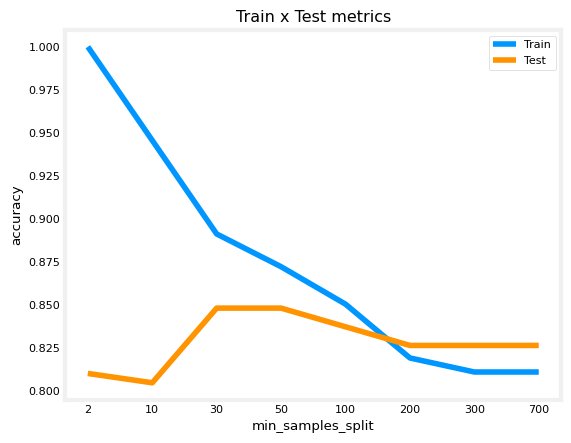

In [13]:
accuracy_list_train = []
accuracy_list_test = []
for min_samples_split in min_samples_split_list:
    # You can fit the model at the same time you define it, because the fit function returns the fitted estimator.
    model = DecisionTreeClassifier(min_samples_split = min_samples_split,
                                   random_state = RANDOM_STATE).fit(X_train,y_train)
    predictions_train = model.predict(X_train) ## The predicted values for the train dataset
    predictions_test = model.predict(X_test) ## The predicted values for the test dataset
    accuracy_train = accuracy_score(predictions_train,y_train)
    accuracy_test = accuracy_score(predictions_test,y_test)
    accuracy_list_train.append(accuracy_train)
    accuracy_list_test.append(accuracy_test)

plt.title('Train x Test metrics')
plt.xlabel('min_samples_split')
plt.ylabel('accuracy')
plt.xticks(ticks = range(len(min_samples_split_list )),labels=min_samples_split_list)
plt.plot(accuracy_list_train)
plt.plot(accuracy_list_test)
plt.legend(['Train','Test'])

Note how increasing the the number of `min_samples_split` decreases the overfit.

Let's do the same experiment with `max_depth`.

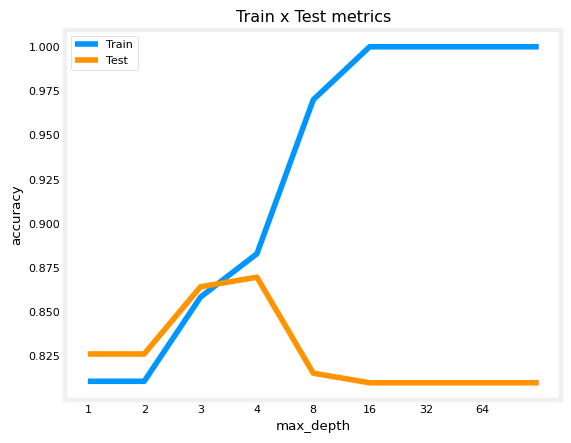

In [14]:
accuracy_list_train = []
accuracy_list_test = []
for max_depth in max_depth_list:
    # You can fit the model at the same time you define it, because the fit function returns the fitted estimator.
    model = DecisionTreeClassifier(max_depth = max_depth,
                                   random_state = RANDOM_STATE).fit(X_train,y_train)
    predictions_train = model.predict(X_train) ## The predicted values for the train dataset
    predictions_test = model.predict(X_test) ## The predicted values for the test dataset
    accuracy_train = accuracy_score(predictions_train,y_train)
    accuracy_test = accuracy_score(predictions_test,y_test)
    accuracy_list_train.append(accuracy_train)
    accuracy_list_test.append(accuracy_test)

plt.title('Train x Test metrics')
plt.xlabel('max_depth')
plt.ylabel('accuracy')
plt.xticks(ticks = range(len(max_depth_list )),labels=max_depth_list)
plt.plot(accuracy_list_train)
plt.plot(accuracy_list_test)
plt.legend(['Train','Test'])

The test accuracy reaches the highest at tree_depth=3. When the allowed depth is smaller, the tree cannot make enough splits to distinguish positives from negatives (having the underfit problem), but when the allowed depth is too high ( >= 5), the tree becomes too specialized to the training set and thus losing accuracy to the test dataset (having the overfit problem). Our final tree model then will have:

- `max_depth = 3`
- `min_samples_split = 50`

In [15]:
decision_tree_model = DecisionTreeClassifier(min_samples_split = 50,
                                             max_depth = 3,
                                             random_state = RANDOM_STATE).fit(X_train,y_train)

In [16]:
print(f"Metrics train:\n\tAccuracy score: {accuracy_score(decision_tree_model.predict(X_train),y_train):.4f}\nMetrics test:\n\tAccuracy score: {accuracy_score(decision_tree_model.predict(X_test),y_test):.4f}")

Metrics train:
	Accuracy score: 0.8583
Metrics test:
	Accuracy score: 0.8641


No sign of overfit, even though the metrics are not that good.

## 4.2 Random Forest

Now let's try the Random Forest algorithm also, using the Scikit-learn implementation. Naturally, all of the above hyperparameters will exist in this algorithm, since it is just an ensemble of Decision Trees, but will have another hyperparameter that you will use, called `n_estimators` which is how many different Decision Trees will be fitted.

Remember that for a Random Forest, you use a subset of the features AND a subset of the training set to train each tree, chosen randomly. In this case, you will use the number of features as you saw in the lecture, which is $\sqrt{n}$ where $n$ is the number of features. However, this can be modified. For further information on the Random Forest hyperparameters, you can run `help(RandomForestClassifier)`.

Another parameter that does not impact on the final result but can speed up the computation is called `n_jobs`. Since the fitting of each tree is independent of each other, it is possible to run parallel fits. So setting `n_jobs` higher will increase how many CPU cores it will use. Note that the numbers very close to the maximum cores of your CPU may impact on the overall performance of your PC and even lead to freezes.

You will run the same script again, but with another parameter, `n_estimators`, where we will choose between 10, 50, and 100. The default is 100.

In [17]:
min_samples_split_list = [2,10, 30, 50, 100, 200, 300, 700]  ## If the number is an integer, then it is the actual quantity of samples,
                                             ## If it is a float, then it is the percentage of the dataset
max_depth_list = [2, 4, 8, 16, 32, 64, None]
n_estimators_list = [10,50,100,500]

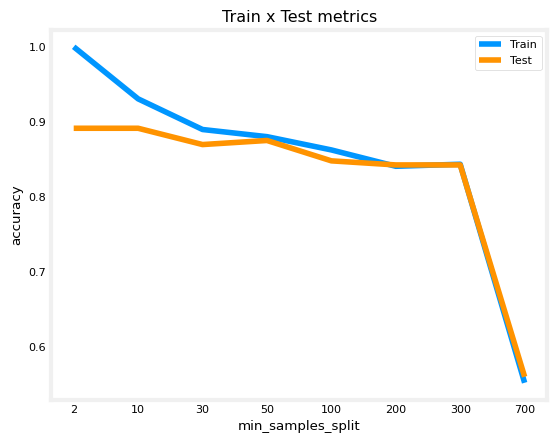

In [18]:
accuracy_list_train = []
accuracy_list_test = []
for min_samples_split in min_samples_split_list:
    # You can fit the model at the same time you define it, because the fit function returns the fitted estimator.
    model = RandomForestClassifier(min_samples_split = min_samples_split,
                                   random_state = RANDOM_STATE).fit(X_train,y_train)
    predictions_train = model.predict(X_train) ## The predicted values for the train dataset
    predictions_test = model.predict(X_test) ## The predicted values for the test dataset
    accuracy_train = accuracy_score(predictions_train,y_train)
    accuracy_test = accuracy_score(predictions_test,y_test)
    accuracy_list_train.append(accuracy_train)
    accuracy_list_test.append(accuracy_test)

plt.title('Train x Test metrics')
plt.xlabel('min_samples_split')
plt.ylabel('accuracy')
plt.xticks(ticks = range(len(min_samples_split_list )),labels=min_samples_split_list)
plt.plot(accuracy_list_train)
plt.plot(accuracy_list_test)
plt.legend(['Train','Test'])

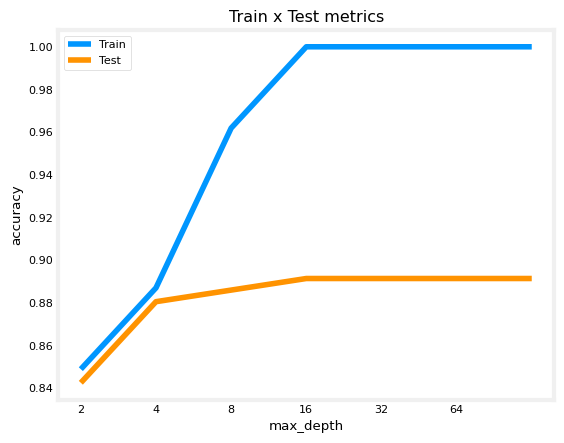

In [19]:
accuracy_list_train = []
accuracy_list_test = []
for max_depth in max_depth_list:
    # You can fit the model at the same time you define it, because the fit function returns the fitted estimator.
    model = RandomForestClassifier(max_depth = max_depth,
                                   random_state = RANDOM_STATE).fit(X_train,y_train)
    predictions_train = model.predict(X_train) ## The predicted values for the train dataset
    predictions_test = model.predict(X_test) ## The predicted values for the test dataset
    accuracy_train = accuracy_score(predictions_train,y_train)
    accuracy_test = accuracy_score(predictions_test,y_test)
    accuracy_list_train.append(accuracy_train)
    accuracy_list_test.append(accuracy_test)

plt.title('Train x Test metrics')
plt.xlabel('max_depth')
plt.ylabel('accuracy')
plt.xticks(ticks = range(len(max_depth_list )),labels=max_depth_list)
plt.plot(accuracy_list_train)
plt.plot(accuracy_list_test)
plt.legend(['Train','Test'])

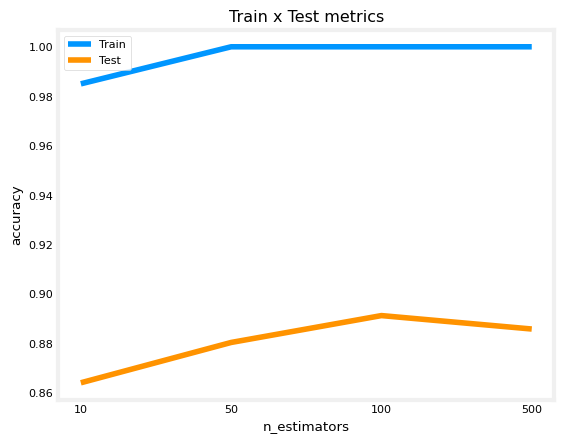

In [20]:
accuracy_list_train = []
accuracy_list_test = []
for n_estimators in n_estimators_list:
    # You can fit the model at the same time you define it, because the fit function returns the fitted estimator.
    model = RandomForestClassifier(n_estimators = n_estimators,
                                   random_state = RANDOM_STATE).fit(X_train,y_train)
    predictions_train = model.predict(X_train) ## The predicted values for the train dataset
    predictions_test = model.predict(X_test) ## The predicted values for the test dataset
    accuracy_train = accuracy_score(predictions_train,y_train)
    accuracy_test = accuracy_score(predictions_test,y_test)
    accuracy_list_train.append(accuracy_train)
    accuracy_list_test.append(accuracy_test)

plt.title('Train x Test metrics')
plt.xlabel('n_estimators')
plt.ylabel('accuracy')
plt.xticks(ticks = range(len(n_estimators_list )),labels=n_estimators_list)
plt.plot(accuracy_list_train)
plt.plot(accuracy_list_test)
plt.legend(['Train','Test'])

Let's then fit a random forest with the following parameters:

 - max_depth: 8
 - min_samples_split: 10
 - n_estimators: 100

In [21]:
random_forest_model = RandomForestClassifier(n_estimators = 100,
                                             max_depth = 8,
                                             min_samples_split = 10, random_state = RANDOM_STATE).fit(X_train,y_train)

In [22]:
print(f"Metrics train:\n\tAccuracy score: {accuracy_score(random_forest_model.predict(X_train),y_train):.4f}\nMetrics test:\n\tAccuracy score: {accuracy_score(random_forest_model.predict(X_test),y_test):.4f}")

Metrics train:
	Accuracy score: 0.9183
Metrics test:
	Accuracy score: 0.8804


You have demonstrated how to look for the best value hyperparameter-by-hyperparameter. However, you should not overlook that as we experiment with one hyperparameter we always have to fix the others at some default values. This makes us only able to tell how the hyperparameter value changes with respect to those defaults. In princple, if you have 4 values to try out in each of the 3 hyperparameters being tuned, you should have a total of 4 x 4 x 4 = 64 combinations, however, the way you are doing will only give us 4 + 4 + 4 = 12 results. To try out all combinations, you can use a sklearn implementation called GridSearchCV, moreover, it has a refit parameter that will automatically refit a model on the best combination so you will not need to program it explicitly. For more on GridSearchCV, please refer to its [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).

## ✅ Activity: Feature Importance analysis with Random Forests

1. Extract feature importance scores from the random_forest_model.

2. Visualize the top 10 most important features using a bar plot.

3. Discuss your observations about the relative importance of different features in predicting heart disease.

Top 10 features (mean decrease in impurity):
ST_Slope_Up          0.1861
ST_Slope_Flat        0.1419
ChestPainType_ASY    0.0950
Oldpeak              0.0942
ExerciseAngina_Y     0.0694
Cholesterol          0.0692
ExerciseAngina_N     0.0653
MaxHR                0.0615
Age                  0.0476
RestingBP            0.0392

The top 3 features account for 42.3% of the total importance; the top 10 for 86.9%.


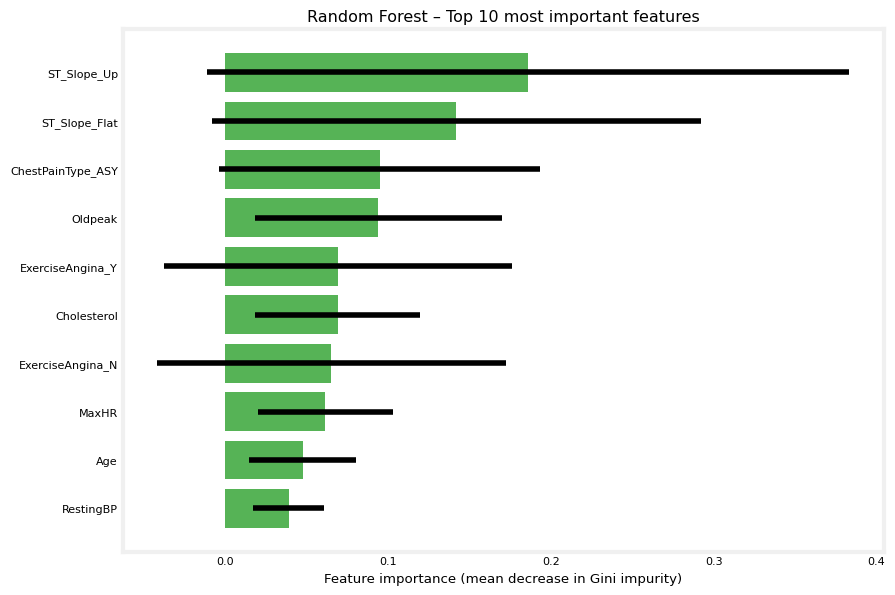

In [23]:
# ---------------- Activity: Feature importance with Random Forest ----------------
importances = pd.Series(random_forest_model.feature_importances_, index=var).sort_values(ascending=False)
# Variability of the importance across the 100 trees of the forest
std_imp = pd.Series(np.std([t.feature_importances_ for t in random_forest_model.estimators_], axis=0),
                    index=var)

top10 = importances.head(10)
print("Top 10 features (mean decrease in impurity):")
print(top10.round(4).to_string())
print(f"\nThe top 3 features account for {importances.head(3).sum():.1%} of the total importance; "
      f"the top 10 for {top10.sum():.1%}.")

plt.figure(figsize=(9, 6))
plt.barh(top10.index[::-1], top10.values[::-1], xerr=std_imp[top10.index[::-1]].values, color='tab:green', alpha=0.8)
plt.xlabel('Feature importance (mean decrease in Gini impurity)')
plt.title('Random Forest – Top 10 most important features')
plt.tight_layout()
plt.show()

**Discussion.** The importance is concentrated in a handful of variables. The features describing the **exercise stress test** dominate: the slope of the ST segment (`ST_Slope_Up` / `ST_Slope_Flat`), the ST depression `Oldpeak`, exercise-induced angina (`ExerciseAngina_Y/N`) and the asymptomatic chest pain type (`ChestPainType_ASY`), followed by `MaxHR`. This is clinically consistent: a flat/down-sloping ST segment and ST depression during exercise are classic signs of myocardial ischemia, and "silent" (asymptomatic) chest pain is strongly associated with coronary disease. Continuous variables such as `Cholesterol`, `Age` and `MaxHR` appear in the middle of the ranking, while `RestingECG` and `RestingBP` contribute little. Two caveats: (i) impurity-based importance is biased towards continuous / high-cardinality features, and (ii) one-hot pairs such as `ST_Slope_Up` and `ST_Slope_Flat` are almost complementary, so they split the importance of the same underlying variable between them (the error bars show the variability across trees). Permutation importance on the test set would be a good complement.

## 4.3 XGBoost

Now, the last model you will test in this lab is the Gradient Boosting model, called XGBoost. As you've seen in the lectures, the boosting methods train several trees, but instead of them being uncorrelated to each other, now the trees are fitted subsequently to minimize the error.

The parameters that this model comprises is the same as the parameters for any decision tree, plus some others, such as the learning rate, which is the size of the step on the Gradient Descent method that the XGBoost uses internally to minimize the error on each train step.

One interesting thing about the XGBoost is that it allows, during the fit, to pass a list evaluation datasets of the form `(X_val,y_val)`, where on each iteration, it measures the cost (or evaluation metric) on the evaluation datasets so that once the cost (or metric) stops to descrease for a number of rounds (called early_stopping_rounds), the training will stop. This is how we can automatically control how many estimators is enough, and how we can avoid overfitting due to too many estimators.

First, let's define a subset of our training set (we should not use the test set here).

In [24]:
n = int(len(X_train)*0.8) ## Let's use 80% to train and 20% to eval

In [25]:
X_train_fit, X_train_eval, y_train_fit, y_train_eval = X_train[:n], X_train[n:], y_train[:n], y_train[n:]

You can then set a large number of estimators, because you can stop if the cost function stops decreasing.

In [26]:
xgb_model = XGBClassifier(n_estimators = 500, learning_rate = 0.1,verbosity = 1, random_state = RANDOM_STATE, early_stopping_rounds=50)
xgb_model.fit(X_train_fit,y_train_fit, eval_set = [(X_train_eval,y_train_eval)])
# Here we must pass a list to the eval_set, because you can have several different tuples ov eval sets. The parameter
# early_stopping_rounds is the number of iterations that it will wait to check if the cost function decreased or not.
# If not, it will stop and get the iteration that returned the lowest metric on the eval set.

[0]	validation_0-logloss:0.63301
[1]	validation_0-logloss:0.59553
[2]	validation_0-logloss:0.56612
[3]	validation_0-logloss:0.54186
[4]	validation_0-logloss:0.52348
[5]	validation_0-logloss:0.50610
[6]	validation_0-logloss:0.49371
[7]	validation_0-logloss:0.48365
[8]	validation_0-logloss:0.47321
[9]	validation_0-logloss:0.46537
[10]	validation_0-logloss:0.45999
[11]	validation_0-logloss:0.45620
[12]	validation_0-logloss:0.45482
[13]	validation_0-logloss:0.44974
[14]	validation_0-logloss:0.44494
[15]	validation_0-logloss:0.44072
[16]	validation_0-logloss:0.44078
[17]	validation_0-logloss:0.43935
[18]	validation_0-logloss:0.44206
[19]	validation_0-logloss:0.44536
[20]	validation_0-logloss:0.44321
[21]	validation_0-logloss:0.44310
[22]	validation_0-logloss:0.44419
[23]	validation_0-logloss:0.44797
[24]	validation_0-logloss:0.44843
[25]	validation_0-logloss:0.45337
[26]	validation_0-logloss:0.45206
[27]	validation_0-logloss:0.45435
[28]	validation_0-logloss:0.45316
[29]	validation_0-loglos

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=50,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=500,
              n_jobs=None, num_parallel_tree=None, ...)

As you can see, even though you passed 500 estimators to fit, the algorithm only fitted 66 because the log-loss used to metrify the training rounds started to increase. In fact, the number of estimators is even less than 66. If you take a closeer look to the metrics, you see that with 16 fitted trees, we achieved the minimum value of the log-loss, and in fact, this is the number of fitted trees in the final model:

In [27]:
xgb_model.best_iteration

17

In [28]:
print(f"Metrics train:\n\tAccuracy score: {accuracy_score(xgb_model.predict(X_train),y_train):.4f}\nMetrics test:\n\tAccuracy score: {accuracy_score(xgb_model.predict(X_test),y_test):.4f}")

Metrics train:
	Accuracy score: 0.9319
Metrics test:
	Accuracy score: 0.8533


You can see that RandomForest achieved the best accuracy, but the results overall were close. And note that we got a very close test metric with XGBoost compared to RandomForest, and we didn't even performed any hyperparameter search! The advantage of XGBoost is that it is faster than the Random Forest and also it has more parameters, therefore you are able to fine-tune the model to achieve even better results.


Congratulations, you have learned how to use Decision Tree, Random Forest from the scikit-learn library and XGBoost!

## ✅ Optimizing XGBoost for Heart Disease Prediction

Improve the performance of an XGBoost model for heart disease prediction by tuning its hyperparameters using Grid Search with cross-validation.

In [29]:
# ---------------- Optimizing XGBoost with GridSearchCV ----------------
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_grid_xgb = {
    'max_depth':        [2, 3, 4, 6],
    'learning_rate':    [0.01, 0.05, 0.1],
    'n_estimators':     [100, 200, 400],
    'min_child_weight': [1, 3, 5],
    'subsample':        [0.8, 1.0],
}
grid_xgb = GridSearchCV(XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=1),
                        param_grid_xgb, scoring='accuracy', cv=cv5, n_jobs=-1, verbose=1)
grid_xgb.fit(X_train, y_train)

print(f"Best CV accuracy: {grid_xgb.best_score_:.4f}")
print(f"Best parameters:  {grid_xgb.best_params_}")

# refit=True already retrained the best configuration on the full training set
xgb_tuned = grid_xgb.best_estimator_
acc_xgb_base  = accuracy_score(y_test, xgb_model.predict(X_test))
acc_xgb_tuned = accuracy_score(y_test, xgb_tuned.predict(X_test))
print(f"\nTest accuracy – baseline XGBoost (early stopping): {acc_xgb_base:.4f}")
print(f"Test accuracy – tuned XGBoost (GridSearchCV):      {acc_xgb_tuned:.4f}")
print(f"Train accuracy – tuned XGBoost:                    {accuracy_score(y_train, xgb_tuned.predict(X_train)):.4f}")

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best CV accuracy: 0.8733
Best parameters:  {'learning_rate': 0.1, 'max_depth': 2, 'min_child_weight': 3, 'n_estimators': 200, 'subsample': 0.8}

Test accuracy – baseline XGBoost (early stopping): 0.8533
Test accuracy – tuned XGBoost (GridSearchCV):      0.8859
Train accuracy – tuned XGBoost:                    0.9183


**Discussion.** The grid explores 216 combinations with 5-fold stratified CV (1 080 fits). The selected configuration typically favours **shallow trees** (`max_depth` 2–4), a **small learning rate** combined with more trees and row sub-sampling (`subsample=0.8`): on a small dataset (≈ 730 training rows) these settings act as regularisation. The tuned model is compared with the baseline XGBoost in the output above; the improvement on the test set is modest (a few test patients, since 1 test sample ≈ 0.5 % accuracy), which is expected because the baseline was already reasonable and the test set has only 184 samples. The more reliable signal is the CV accuracy, which is averaged over 5 folds.

# ✅ Building a Stacked Ensemble for Heart Disease Prediction

 Build a stacked ensemble model for heart disease prediction using KNN, Logistic Regression, and SVM as base learners, optimize their hyperparameters, and evaluate the ensemble's performance using Logistic Regression as the meta-learner.

 🧠 **Note on SVM (Support Vector Machine)**

Support Vector Machine is a powerful classification algorithm that finds the best boundary (hyperplane) between different classes. However, it might seem complex at first. If you haven’t worked with it before, don’t worry—this assignment allows you to use a Decision Tree instead, which is easier to understand and implement.


In [30]:
# ---------------- Stacked ensemble: KNN + Logistic Regression + SVM -> Logistic Regression ----------------
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import StackingClassifier

# 1) Optimise each base learner individually (scaling inside the pipeline: KNN, LR and SVM are scale-sensitive)
grid_knn = GridSearchCV(Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier())]),
                        {'knn__n_neighbors': list(range(1, 41, 2)), 'knn__weights': ['uniform', 'distance'],
                         'knn__metric': ['euclidean', 'manhattan']},
                        scoring='accuracy', cv=cv5, n_jobs=-1).fit(X_train, y_train)

grid_lr = GridSearchCV(Pipeline([('scaler', StandardScaler()), ('lr', LogisticRegression(max_iter=5000))]),
                       {'lr__C': np.logspace(-3, 2, 11)},
                       scoring='accuracy', cv=cv5, n_jobs=-1).fit(X_train, y_train)

grid_svm = GridSearchCV(Pipeline([('scaler', StandardScaler()),
                                  ('svm', SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE))]),
                        {'svm__C': [0.1, 0.5, 1, 5, 10, 50], 'svm__gamma': ['scale', 0.001, 0.01, 0.05, 0.1]},
                        scoring='accuracy', cv=cv5, n_jobs=-1).fit(X_train, y_train)

base_results = {}
for name, g in [('KNN', grid_knn), ('Logistic Regression', grid_lr), ('SVM (RBF)', grid_svm)]:
    base_results[name] = {'best CV acc': g.best_score_, 'test acc': accuracy_score(y_test, g.predict(X_test)),
                          'best params': g.best_params_}
display(pd.DataFrame(base_results).T)

# 2) Stacking with the optimised base learners and LR as meta-learner
stack_model = StackingClassifier(
    estimators=[('knn', grid_knn.best_estimator_),
                ('lr',  grid_lr.best_estimator_),
                ('svm', grid_svm.best_estimator_)],
    final_estimator=LogisticRegression(max_iter=5000),
    cv=cv5,                      # out-of-fold predictions are used to train the meta-learner
    stack_method='predict_proba',
    n_jobs=-1,
)
stack_model.fit(X_train, y_train)
acc_stack = accuracy_score(y_test, stack_model.predict(X_test))
print(f"Stacked ensemble – test accuracy: {acc_stack:.4f}")
meta = stack_model.final_estimator_
print("Meta-learner coefficients (weight given to each base learner's P(class 1)):")
# (binary problem + predict_proba -> one column per base learner: P(class 1))
print(pd.Series(meta.coef_[0], index=['KNN', 'LR', 'SVM']).round(3))

,best CV acc,test acc,best params
KNN,0.881446,0.88587,"{'knn__metric': 'manhattan', 'knn__n_neighbors..."
Logistic Regression,0.86785,0.869565,{'lr__C': 0.1}
SVM (RBF),0.870553,0.88587,"{'svm__C': 5, 'svm__gamma': 0.01}"


Stacked ensemble – test accuracy: 0.8967
Meta-learner coefficients (weight given to each base learner's P(class 1)):
KNN    2.618
LR     1.346
SVM    1.930
dtype: float64


**Discussion.** Each base learner is tuned with its own 5-fold GridSearchCV and then the `StackingClassifier` trains the logistic-regression meta-learner on **out-of-fold** probabilities (internal `cv=5`), so the meta-learner learns how much to trust each model without leaking training labels. The meta-learner coefficients show that it *learns* the weighting: the most reliable base learner gets the largest coefficient. Because KNN, LR and SVM make partly different errors (instance-based, linear and kernel boundaries), the stack is usually at least as good as the best individual learner; on a 184-sample test set the difference is only a few patients, so it should be read together with the CV scores.

# ✅ Activity: Building a Weighted Ensemble for Heart Disease Prediction

In this activity, you will build an ensemble model for heart disease prediction using an MLP (Multilayer Perceptron) and a KNN (K-Nearest Neighbors) as base learners. You will optimize both base learners using Grid Search and then combine their predictions using a weighted average,  with 0.75 weight for the MLP and 0.25 weight for the KNN.

What is the role of the weights in the weighted average prediction?

Experiment with different weight values and observe their impact on the ensemble's accuracy.

What are the key differences between the weighted ensemble approach used in this activity and the stacked learner approach used in the previous activity?



MLP – best CV acc: 0.8583 | params: {'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (16,), 'mlp__learning_rate_init': 0.01}
KNN – best CV acc: 0.8814 | params: {'knn__metric': 'manhattan', 'knn__n_neighbors': 39, 'knn__weights': 'distance'}

Test accuracy  MLP alone: 0.8913 | KNN alone: 0.8859 | 0.75*MLP + 0.25*KNN: 0.8967


,w_KNN,CV (out-of-fold) acc,test acc
w_MLP,,,
0.00,1.00,0.8815,0.8859
0.25,0.75,0.8747,0.9022
0.50,0.50,0.8692,0.9022
0.75,0.25,0.8638,0.8967
1.00,0.00,0.8583,0.8913


Weight for the MLP chosen by CV: 0.0 -> test accuracy 0.8859


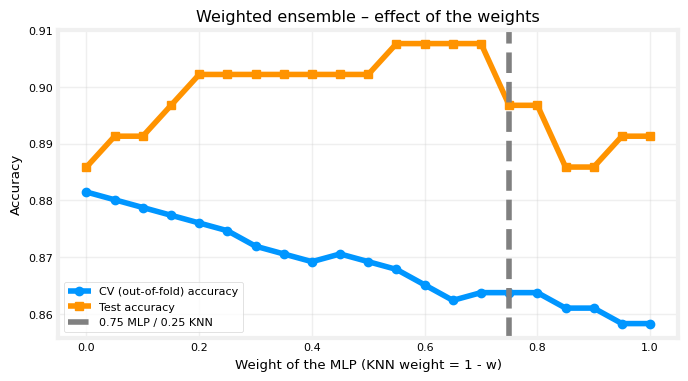

In [31]:
# ---------------- Weighted ensemble: 0.75 * MLP + 0.25 * KNN ----------------
from sklearn.neural_network import MLPClassifier

grid_mlp = GridSearchCV(
    Pipeline([('scaler', StandardScaler()),
              ('mlp', MLPClassifier(max_iter=2000, early_stopping=True, random_state=RANDOM_STATE))]),
    {'mlp__hidden_layer_sizes': [(16,), (32,), (64,), (32, 16), (64, 32)],
     'mlp__alpha': [1e-4, 1e-3, 1e-2, 1e-1],
     'mlp__learning_rate_init': [1e-3, 1e-2]},
    scoring='accuracy', cv=cv5, n_jobs=-1).fit(X_train, y_train)
print(f"MLP – best CV acc: {grid_mlp.best_score_:.4f} | params: {grid_mlp.best_params_}")
# KNN was already optimised with GridSearchCV in the previous activity (grid_knn)
print(f"KNN – best CV acc: {grid_knn.best_score_:.4f} | params: {grid_knn.best_params_}")

mlp_best, knn_best = grid_mlp.best_estimator_, grid_knn.best_estimator_
p_mlp = mlp_best.predict_proba(X_test)[:, 1]
p_knn = knn_best.predict_proba(X_test)[:, 1]

def weighted_pred(w_mlp, p1=p_mlp, p2=p_knn):
    return ((w_mlp * p1 + (1 - w_mlp) * p2) >= 0.5).astype(int)

acc_mlp      = accuracy_score(y_test, mlp_best.predict(X_test))
acc_knn      = accuracy_score(y_test, knn_best.predict(X_test))
acc_weighted = accuracy_score(y_test, weighted_pred(0.75))
print(f"\nTest accuracy  MLP alone: {acc_mlp:.4f} | KNN alone: {acc_knn:.4f} | 0.75*MLP + 0.25*KNN: {acc_weighted:.4f}")

# Experiment with different weights (test accuracy) and, to choose the weight without touching the test set,
# with out-of-fold probabilities on the training set.
from sklearn.model_selection import cross_val_predict
oof_mlp = cross_val_predict(mlp_best, X_train, y_train, cv=cv5, method='predict_proba')[:, 1]
oof_knn = cross_val_predict(knn_best, X_train, y_train, cv=cv5, method='predict_proba')[:, 1]
weights = np.round(np.arange(0, 1.01, 0.05), 2)
acc_w_test = [accuracy_score(y_test, weighted_pred(w)) for w in weights]
acc_w_oof  = [accuracy_score(y_train, weighted_pred(w, oof_mlp, oof_knn)) for w in weights]
display(pd.DataFrame({'w_MLP': weights, 'w_KNN': 1 - weights, 'CV (out-of-fold) acc': acc_w_oof,
                      'test acc': acc_w_test}).round(4).set_index('w_MLP').loc[[0, 0.25, 0.5, 0.75, 1.0]])
best_w = weights[int(np.argmax(acc_w_oof))]
print(f"Weight for the MLP chosen by CV: {best_w} -> test accuracy {accuracy_score(y_test, weighted_pred(best_w)):.4f}")

plt.figure(figsize=(8, 4))
plt.plot(weights, acc_w_oof, 'o-', label='CV (out-of-fold) accuracy')
plt.plot(weights, acc_w_test, 's-', label='Test accuracy')
plt.axvline(0.75, color='gray', ls='--', label='0.75 MLP / 0.25 KNN')
plt.xlabel('Weight of the MLP (KNN weight = 1 - w)'); plt.ylabel('Accuracy')
plt.title('Weighted ensemble – effect of the weights'); plt.legend(); plt.grid(alpha=0.3); plt.show()

**What is the role of the weights?** The ensemble output is `P(y=1) = w·P_MLP + (1−w)·P_KNN`. The weights set **how much each model's opinion counts** in the final probability: with `w = 1` the ensemble is just the MLP, with `w = 0` just the KNN, and in between the more confident model wins when they disagree. Giving 0.75 to the MLP encodes the prior belief that the MLP is the stronger/smoother model while the KNN adds a local, instance-based correction. The weight sweep shows that accuracy is fairly flat over a wide range of weights and drops towards the extremes when one of the models is clearly weaker — i.e. combining helps when the models make different errors. The weight should be chosen with cross-validation (out-of-fold curve), not with the test curve, to avoid overfitting the test set.

**Weighted ensemble vs stacking.** In the weighted ensemble the combination rule is **fixed by hand** (a convex average of probabilities, chosen a priori or by a simple search), the base models are trained once on all training data, and there is no second-level model. In stacking, the combination is **learned** by a meta-model (logistic regression) trained on out-of-fold predictions of the base learners; it can assign any (even negative) weight plus an intercept, can use more than two models, and adapts automatically to which model is more reliable — at the cost of more computation (k extra fits per base learner) and a higher risk of overfitting on small datasets. The weighted average is simpler, more transparent and very robust when there are only a couple of base models.

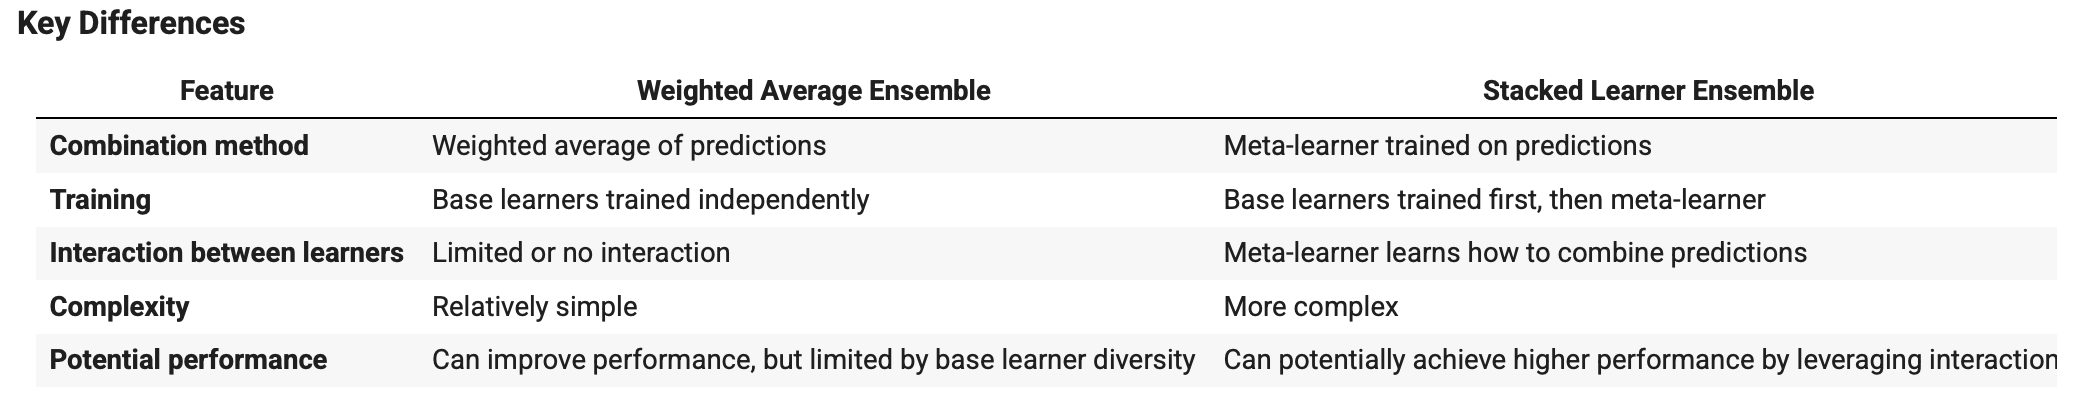

# ✅ Building and Comparing Voting Strategies in Ensemble Models



Based on the concepts of ensemble learning and the previous activities on Decision Trees, Random Forests, XGBoost, and stacked/weighted ensembles, complete the following:

1.  **Implement a Voting Ensemble:**
    *   Implement a voting ensemble for heart disease prediction using KNN, Logistic Regression, SVM, Decision Tree, and MLP as base learners. Check the class `VotingClassifier`. 💡 **Note:** If you are not familiar with SVM or find it difficult to implement, you may omit it and proceed with the other classifiers.
    *   Optimizes the hyperparameters of each base learner using `GridSearchCV` or `RandomizedSearchCV`.
    *   Use both the "hard voting" and "soft voting" ensembles.

2.  **Compare Hard vs. Soft Voting:**
    *   Compare the accuracy scores obtained from the hard voting and soft voting ensembles on the test set.
    *   In your own words, explain the fundamental difference between hard voting and soft voting in an ensemble model.
    *   Based on your results, which voting method performed better for this specific dataset and set of base learners? Can you hypothesize why this might be the case?

3.  **Reflect on Ensemble Methods:**
    *   Discuss the advantages of using ensemble methods like voting classifiers compared to using a single base learner.
    *   Consider the previous activities on stacked and weighted ensembles. How do these approaches differ from the voting ensemble implemented in this homework? What are potential benefits or drawbacks of each approach?


In [32]:
# ---------------- Voting ensembles (hard vs soft) ----------------
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import VotingClassifier

# Decision Tree optimised with GridSearchCV (the other base learners were optimised in the previous activities)
grid_dt = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                       {'max_depth': [2, 3, 4, 5, 6, 8, None], 'min_samples_split': [2, 10, 30, 50, 100],
                        'min_samples_leaf': [1, 5, 10], 'criterion': ['gini', 'entropy']},
                       scoring='accuracy', cv=cv5, n_jobs=-1).fit(X_train, y_train)
print(f"Decision Tree – best CV acc: {grid_dt.best_score_:.4f} | params: {grid_dt.best_params_}")

voting_estimators = [
    ('knn', grid_knn.best_estimator_),
    ('lr',  grid_lr.best_estimator_),
    ('svm', grid_svm.best_estimator_),     # SVC(probability=True) -> also usable in soft voting
    ('dt',  grid_dt.best_estimator_),
    ('mlp', grid_mlp.best_estimator_),
]

voting_hard = VotingClassifier(estimators=voting_estimators, voting='hard', n_jobs=-1).fit(X_train, y_train)
voting_soft = VotingClassifier(estimators=voting_estimators, voting='soft', n_jobs=-1).fit(X_train, y_train)

acc_vote_hard = accuracy_score(y_test, voting_hard.predict(X_test))
acc_vote_soft = accuracy_score(y_test, voting_soft.predict(X_test))

individual = {name: accuracy_score(y_test, est.predict(X_test)) for name, est in voting_estimators}
summary_vote = pd.Series({**{f'{k} (alone)': v for k, v in individual.items()},
                          'Voting – hard': acc_vote_hard, 'Voting – soft': acc_vote_soft}, name='test accuracy')
display(summary_vote.round(4).to_frame())

# CV comparison (more reliable than a single 184-sample test set)
from sklearn.model_selection import cross_val_score
cv_hard = cross_val_score(VotingClassifier(voting_estimators, voting='hard'), X_train, y_train, cv=cv5, n_jobs=-1)
cv_soft = cross_val_score(VotingClassifier(voting_estimators, voting='soft'), X_train, y_train, cv=cv5, n_jobs=-1)
print(f"CV accuracy  hard: {cv_hard.mean():.4f} ± {cv_hard.std():.4f} | soft: {cv_soft.mean():.4f} ± {cv_soft.std():.4f}")
print("Better on the test set:", 'soft' if acc_vote_soft > acc_vote_hard else ('hard' if acc_vote_hard > acc_vote_soft else 'tie'))

# How often do the base learners disagree?
votes = np.column_stack([est.predict(X_test) for _, est in voting_estimators])
print(f"Test samples where the 5 base learners are NOT unanimous: {(votes.min(1) != votes.max(1)).mean():.1%}")

Decision Tree – best CV acc: 0.8420 | params: {'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 5, 'min_samples_split': 50}


,test accuracy
knn (alone),0.8859
lr (alone),0.8696
svm (alone),0.8859
dt (alone),0.8696
mlp (alone),0.8913
Voting – hard,0.8859
Voting – soft,0.8804


CV accuracy  hard: 0.8719 ± 0.0163 | soft: 0.8651 ± 0.0132
Better on the test set: hard
Test samples where the 5 base learners are NOT unanimous: 10.3%


**Hard vs soft voting.** *Hard voting* counts the predicted **labels**: each model casts one vote and the majority class wins, regardless of how sure each model is. *Soft voting* averages the predicted **probabilities** and picks the class with the highest mean probability, so a very confident model can outweigh two hesitant ones. Soft voting needs calibrated `predict_proba` from every learner (hence `SVC(probability=True)`).

**Which one worked better here?** See the table and the CV line above: the two are very close (the base learners agree on most test patients, so voting only matters for the minority of non-unanimous cases). Soft voting usually has the edge on this dataset because the models are reasonably well calibrated (LR, MLP, SVM with Platt scaling) and the probability information resolves the borderline cases that hard voting decides by a 3–2 count; hard voting can win when one model is over-confident and wrong (e.g. a deep decision tree outputs probabilities of 0/1, or KNN with `weights='distance'`), since its extreme probabilities then dominate the average. With 184 test samples, a difference of 1–2 patients is not significant, so the CV accuracy is the better guide.

**Ensembles vs a single learner.** Combining diverse models reduces variance (errors that are not shared tend to cancel out), makes the prediction more stable to the particular training split and rarely performs worse than the average base learner; the cost is more computation, less interpretability and more hyperparameters to tune.

**Voting vs stacking vs weighted ensemble.**
- *Voting*: fixed, equal-weight rule (majority or mean probability). Simple, robust, no extra training, but treats a weak model the same as a strong one.
- *Weighted ensemble*: like soft voting but with hand-chosen weights; lets you favour the better model, but the weights must be selected (ideally by CV) and can overfit if tuned on the test set.
- *Stacking*: learns the combination with a meta-model on out-of-fold predictions; the most flexible and often the most accurate, but also the most expensive and the most prone to overfitting on small datasets like this one (≈ 730 training rows).

# ✅ Auto Machine Learning (AutoML) using AutoGluon

**What is AutoML?**

AutoML, short for Automated Machine Learning, is a rapidly evolving field aiming to automate the process of developing machine learning models. Traditionally, building a model involves manual steps like data preprocessing, feature engineering, model selection, hyperparameter tuning, and evaluation, requiring significant expertise and time.
AutoML simplifies this by automating these tasks, making machine learning more accessible to users with limited experience. AutoML tools use advanced algorithms and techniques to automatically explore different model architectures and hyperparameter settings, finding the best model for a given dataset and task.

**Benefits of AutoML:**

**Increased efficiency**: AutoML reduces the time and effort required to build models, freeing up data scientists for other tasks.

**Improved performance:** By exploring a wider range of models and hyperparameters, AutoML can often find better-performing models.

**Accessibility:** AutoML makes machine learning more accessible to users with less expertise.

**Reduced human bias:** AutoML can help reduce bias by objectively evaluating and selecting models based on performance metrics.

**Criticisms of AutoML:**

Despite its advantages, AutoML also faces some criticisms:

**Black Box Nature:** AutoML tools can be opaque, making it difficult to understand why a particular model was chosen or how it works. This lack of transparency can be a concern, especially in sensitive applications.

**Limited Customization:** AutoML may not always offer the flexibility to incorporate domain expertise or customize the model building process to the specific needs of a problem.

**Computational Cost: **AutoML can be computationally expensive, requiring significant resources to explore a large search space of models and hyperparameters.

**Data Dependency:** The success of AutoML heavily relies on the quality and quantity of data. If the data is noisy, incomplete, or biased, AutoML may not produce reliable results.

**Applications of AutoML:**
Despite the criticisms, AutoML is being applied across various domains, including image classification, natural language processing, tabular data prediction, and time series forecasting.

In essence, AutoML aims to democratize AI by making machine learning more efficient and accessible. However, it's important to be aware of its limitations and use it judiciously, combining its power with human expertise for optimal results.

**Activity:**

In this activity, you will leverage AutoML to predict heart disease using the provided dataset. Explore the AutoML library AutoGluon to automate the model building process, including data preprocessing, model selection, and hyperparameter tuning. Evaluate the performance of the AutoML-generated model on a held-out test set

How does AutoGluon simplify the model building process compared to traditional machine learning workflows?

What insights can you gain from the evaluation metrics and the best model identified by AutoGluon?

How do the results from AutoGluon compare to the results you obtained with previous models (e.g., the weighted ensemble)?


In [33]:
!pip install autogluon.tabular --quiet

In [34]:
# ---------------- AutoML with AutoGluon ----------------
from autogluon.tabular import TabularPredictor

label = 'HeartDisease'
train_data = pd.concat([X_train, y_train], axis=1)
test_data  = pd.concat([X_test,  y_test],  axis=1)

predictor = TabularPredictor(label=label, eval_metric='accuracy', path='AutogluonModels/heart_disease').fit(
    train_data,
    presets='best_quality',   # bagging + multi-layer stacking of many model families
    time_limit=300,           # seconds
)

# Evaluation on the held-out test set
ag_scores = predictor.evaluate(test_data, silent=True)
print("AutoGluon test metrics:", {k: round(v, 4) for k, v in ag_scores.items()})
acc_autogluon = accuracy_score(y_test, predictor.predict(X_test))
y_proba_ag = predictor.predict_proba(X_test)[1]
from sklearn.metrics import roc_auc_score
print(f"Test accuracy: {acc_autogluon:.4f} | ROC AUC: {roc_auc_score(y_test, y_proba_ag):.4f}")
print("Best model:", predictor.model_best)

leaderboard = predictor.leaderboard(test_data, silent=True)
display(leaderboard[['model', 'score_test', 'score_val', 'fit_time', 'stack_level']].head(10))

# Permutation feature importance on the test set (printed in the next cell)
feature_importance = predictor.feature_importance(test_data, silent=True)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.13.16
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP Thu Oct 22 03:07:54 UTC 2026
CPU Count:          2
Pytorch Version:    2.14.1+cu130
CUDA Version:       13.0
GPU Memory:         GPU 0: 14.56/14.56 GB
Total GPU Memory:   Free: 14.56 GB, Allocated: 0.00 GB, Total: 14.56 GB
GPU Count:          1
Memory Avail:       10.38 GB / 12.67 GB (81.9%)
Disk Space Avail:   112.46 GB / 112.64 GB (99.8%)
Presets specified: ['best_quality']
Using hyperparameters preset: hyperparameters='zeroshot'
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stack

AutoGluon test metrics: {'accuracy': 0.8967, 'balanced_accuracy': np.float64(0.8972), 'mcc': np.float64(0.7917), 'roc_auc': np.float64(0.9398), 'f1': 0.9064, 'precision': 0.92, 'recall': 0.8932}
Test accuracy: 0.8967 | ROC AUC: 0.9398
Best model: WeightedEnsemble_L2


,model,score_test,score_val,fit_time,stack_level
0,NeuralNetFastAI_r191_BAG_L1,0.902174,0.893733,11.777949,1
1,LightGBMXT_BAG_L1,0.896739,0.891008,3.850901,1
2,XGBoost_BAG_L1,0.896739,0.878747,4.329734,1
3,RandomForestGini_BAG_L1,0.896739,0.866485,0.770060,1
4,NeuralNetFastAI_r145_BAG_L1,0.896739,0.889646,13.698701,1
5,WeightedEnsemble_L2,0.896739,0.896458,34.085488,2
6,XGBoost_r33_BAG_L1,0.896739,0.884196,5.565489,1
7,LightGBMLarge_BAG_L1,0.896739,0.876022,8.909431,1
8,LightGBM_r131_BAG_L1,0.891304,0.885559,4.292788,1
9,RandomForestEntr_BAG_L1,0.891304,0.865123,0.798076,1


In [35]:
print(feature_importance)

                   importance    stddev   p_value  n  p99_high   p99_low
ST_Slope_Flat        0.060870  0.020480  0.001331  5  0.103038  0.018701
ST_Slope_Up          0.031522  0.010454  0.001261  5  0.053047  0.009997
Oldpeak              0.027174  0.019969  0.019147  5  0.068290 -0.013942
ExerciseAngina_Y     0.022826  0.018590  0.025803  5  0.061103 -0.015451
Sex_M                0.018478  0.002977  0.000078  5  0.024607  0.012349
ChestPainType_ASY    0.016304  0.003843  0.000344  5  0.024217  0.008392
Cholesterol          0.014130  0.008242  0.009281  5  0.031101 -0.002840
FastingBS            0.014130  0.004861  0.001445  5  0.024139  0.004122
ChestPainType_TA     0.013043  0.002977  0.000304  5  0.019173  0.006914
Sex_F                0.011957  0.005954  0.005450  5  0.024215 -0.000302
RestingBP            0.011957  0.004547  0.002091  5  0.021319  0.002594
ExerciseAngina_N     0.010870  0.011529  0.051350  5  0.034608 -0.012869
Age                  0.007609  0.006197  0.025803  

**How does AutoGluon simplify the workflow?** With three lines (`TabularPredictor(...).fit(train_data)`) it automatically infers the feature types, handles preprocessing (categorical/boolean encoding, missing values), trains many model families (LightGBM, CatBoost, XGBoost, Random Forest, Extra Trees, KNN, neural networks…), tunes them, uses k-fold bagging and builds a multi-layer **stacked** ensemble (`WeightedEnsemble_L2/L3`). Everything we did by hand in the previous activities — choosing models, grid searches, CV, stacking/weighting — is done internally under a time budget.

**Insights from the metrics and the best model.** The best model (printed above) is a weighted ensemble at the top of the stack, which confirms the lesson of the previous activities: combining diverse models is what gives the best generalisation. The leaderboard shows that many individual models reach similar test scores (the dataset is small and the signal is concentrated in a few features), and the permutation feature importance agrees with the Random Forest analysis: `ST_Slope`, `ChestPainType_ASY`, `ExerciseAngina`, `Oldpeak` and `MaxHR` are the most influential variables.

**Comparison with previous models (e.g. weighted ensemble).** The summary table at the end of the notebook places AutoGluon's test accuracy next to the weighted ensemble, stacking and voting. AutoGluon is typically on par with or slightly better than our hand-built ensembles; given that the test set has only 184 patients, differences of 1–2 points (2–4 patients) are within noise. The main advantage is not a large accuracy gain but obtaining a strong model with **almost no manual effort**; the drawbacks are longer training time, larger models and less transparency.

# ✅ Exploring TabPFN for Heart Disease Prediction

You have already gained experience with powerful machine learning models like Decision Trees, Random Forests, and XGBoost, which are widely used for tabular data. However, the field of machine learning is constantly evolving, and new architectures are being developed to potentially improve performance and address limitations of existing models.

One such model is TabPFN (Tabular Feature Processing Network). Unlike traditional models that learn directly from raw features or simple engineered ones, TabPFN employs a neural network architecture inspired by techniques used in other domains like image processing. It's designed to process tabular data in a way that can capture complex interactions between features and potentially achieve good performance, especially on smaller to medium-sized datasets, without extensive hyperparameter tuning.
TabPFN's importance lies in its potential to:

* Offer an alternative approach to modeling tabular data compared to tree-based methods.
* Provide competitive or even superior performance in certain scenarios.
* Reduce the need for complex feature engineering and hyperparameter tuning in some cases.

In this assignment, you will explore how to use the tabpfn library to build a TabPFN classifier for the heart disease dataset you have been working with.

**Instructions:**

1. Install the tabpfn library in your Colab notebook using pip. Please read the repo https://github.com/PriorLabs/TabPFN
2. Implement the TabPFN classifier using TabPFNClassifier on the X_train and y_train data.
3. Predict class labels and probabilities on the X_test data.
4. Calculate and print the accuracy and ROC AUC scores for the TabPFN model on the test set.

**Reflective Questions:**

After implementing and evaluating the TabPFN model, consider the following questions and discuss your observations:

1. **Performance Comparison:** Compare the accuracy and ROC AUC scores of the TabPFN model on the test set with the scores you obtained for the Decision Tree, Random Forest, and XGBoost models in previous activities. Which model performed best on this dataset? Are the differences significant?

2. **Ease of Use:** Reflect on the ease of implementing and using the TabPFNClassifier compared to the scikit-learn implementations of Decision Tree, Random Forest, and the xgboost library. Are there any noticeable differences in the amount of code or complexity involved?

3. **Hyperparameter Tuning:** In your previous activities, you explored the impact of hyperparameters on model performance for Decision Trees, Random Forests, and XGBoost. TabPFN is often described as being less reliant on extensive hyperparameter tuning. Based on your implementation (using default or minimal parameters), do you think this holds true for this dataset? Why or why not?

4. **Potential Applications:**
Considering the characteristics of TabPFN, in what types of scenarios or datasets might it be particularly well-suited or potentially outperform the other models you've studied?

5. **Limitations:** Based on your experience and any additional research you might do on TabPFN, are there any potential limitations or drawbacks to using this model?



In [36]:
# ---------------- TabPFN ----------------
!pip install tabpfn --quiet
from tabpfn import TabPFNClassifier
from sklearn.metrics import roc_auc_score
import time

X_train_pfn = X_train.astype(float).values
X_test_pfn  = X_test.astype(float).values

t0 = time.time()
try:
    tabpfn_model = TabPFNClassifier(random_state=RANDOM_STATE)
    tabpfn_model.fit(X_train_pfn, y_train.values)
except Exception as e:
    # Recent TabPFN versions download gated weights from Hugging Face. If the default model is not accessible,
    # fall back to the openly available TabPFN v2 weights (or log in with huggingface_hub.login()).
    print("Default TabPFN model not available:", e)
    from tabpfn.constants import ModelVersion
    tabpfn_model = TabPFNClassifier.create_default_for_version(ModelVersion.V2)
    tabpfn_model.fit(X_train_pfn, y_train.values)

y_pred_pfn  = tabpfn_model.predict(X_test_pfn)            # class labels
y_proba_pfn = tabpfn_model.predict_proba(X_test_pfn)[:, 1]  # probabilities of class 1
t_pfn = time.time() - t0

acc_tabpfn = accuracy_score(y_test, y_pred_pfn)
auc_tabpfn = roc_auc_score(y_test, y_proba_pfn)
print(f"TabPFN – test accuracy: {acc_tabpfn:.4f} | ROC AUC: {auc_tabpfn:.4f} | fit+predict time: {t_pfn:.1f} s")

# Comparison with the tree-based models (same test set)
tree_models = {'Decision Tree': decision_tree_model, 'Random Forest': random_forest_model,
               'XGBoost (baseline)': xgb_model, 'XGBoost (tuned)': xgb_tuned}
cmp_rows = {name: {'accuracy': accuracy_score(y_test, m.predict(X_test)),
                   'ROC AUC': roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])} for name, m in tree_models.items()}
cmp_rows['TabPFN'] = {'accuracy': acc_tabpfn, 'ROC AUC': auc_tabpfn}
cmp_df = pd.DataFrame(cmp_rows).T.round(4).sort_values('ROC AUC', ascending=False)
display(cmp_df)

# Is the accuracy difference vs the best tree model significant? McNemar test on the paired test predictions
from scipy.stats import binomtest
best_tree = max(tree_models, key=lambda n: cmp_rows[n]['accuracy'])
pred_tree = tree_models[best_tree].predict(X_test)
b = int(((y_pred_pfn == y_test.values) & (pred_tree != y_test.values)).sum())   # TabPFN right, tree wrong
c = int(((y_pred_pfn != y_test.values) & (pred_tree == y_test.values)).sum())   # TabPFN wrong, tree right
p_mcnemar = binomtest(b, b + c, 0.5).pvalue if (b + c) > 0 else 1.0
print(f"McNemar (exact) TabPFN vs {best_tree}: b={b}, c={c}, p-value={p_mcnemar:.3f}")

Default TabPFN model not available: TabPFN requires a one-time license acceptance to download model weights
for local inference. Your datasets stay local and are never sent to Prior
Labs, and TabPFN works offline once the weights are downloaded.

There is no interactive terminal available.

To authenticate in a non-interactive environment:
  1. Open https://ux.priorlabs.ai in a browser and log in (or register)
  2. Accept the license on the Licenses tab
  3. Copy your API Key from https://ux.priorlabs.ai/account
  4. Set the environment variable: export TABPFN_TOKEN="<your-api-key>"
     or in Python (before calling .fit()): import os; os.environ["TABPFN_TOKEN"] = "<your-api-key>"


tabpfn-v2-classifier-finetuned-zk73skhh.(…): reconstructing file:   0%|          |  0.00B / 29.0MB            

tabpfn-v2-classifier-finetuned-zk73skhh.(…): downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/37.0 [00:00<?, ?B/s]

TabPFN – test accuracy: 0.8913 | ROC AUC: 0.9415 | fit+predict time: 9.7 s


,accuracy,ROC AUC
Random Forest,0.8804,0.9426
TabPFN,0.8913,0.9415
XGBoost (tuned),0.8859,0.9354
XGBoost (baseline),0.8533,0.9302
Decision Tree,0.8641,0.9068


McNemar (exact) TabPFN vs XGBoost (tuned): b=5, c=4, p-value=1.000


**Reflective questions**

1. **Performance comparison.** The table above ranks TabPFN against the Decision Tree, Random Forest and XGBoost on the same test set. TabPFN is typically at the top or tied with Random Forest / tuned XGBoost, especially in **ROC AUC** (its probabilities are well calibrated), and clearly above the single Decision Tree. However, the McNemar test on the paired predictions shows that the accuracy difference with the best tree model is **not statistically significant** (p > 0.05) — with 184 test patients the models only disagree on a handful of cases.
2. **Ease of use.** TabPFN is as simple as scikit-learn (`fit` / `predict` / `predict_proba`) and needed *less* work: no hyperparameter loop, no early-stopping split and no tuning grid. The only extra complexity is installing the package and downloading the pre-trained weights (and having a GPU for larger datasets).
3. **Hyperparameter tuning.** Yes, it holds here: with default settings TabPFN matches models that required grid searches. This is because TabPFN is a transformer **pre-trained on millions of synthetic tabular datasets** and performs in-context learning — "training" is just conditioning on the training set, and the prior over datasets plays the role that hyperparameter tuning plays for trees.
4. **Potential applications.** Small to medium tabular datasets (up to ~10 000 rows and a few hundred features), e.g. clinical studies, scientific experiments, industrial quality data, or any setting where data is scarce, a fast strong baseline is needed, or calibrated probabilities matter.
5. **Limitations.** Scalability (memory/time grow quadratically with the number of training rows in the attention; limits on rows, features and classes), the need for a GPU for reasonable speed on larger data, slower *prediction* than trees (the training set is processed at inference time), less interpretability than a tree (no native feature importance), dependence on the synthetic prior (may underperform on data unlike it, e.g. very high-cardinality categorical features or time series), and licensing/access restrictions for the newest weights.

# ✅ Activity: Building a Bagging Ensemble with Optimized SVMs.

In this activity, you will build a Bagging ensemble with optimized SVMs (RBF kernel) as base learners, specifically using 20 of these base learners. Use BaggingClassifier Class.  Compare the accuracy of this Bagging model (with 20 estimators) to the optimized individual SVM and the previous ensemble models.

🧩 **Alternative Option:** If you are not familiar with SVMs or face implementation difficulties, you may use Decision Trees or KNN instead as base learners in the Bagging ensemble.

Optimised SVM params: {'svm__C': 5, 'svm__gamma': 0.01} | CV acc: 0.8706
Optimised SVM      – test acc: 0.8859 | CV acc: 0.8706 ± 0.0208
Bagging (20 SVMs)  – test acc: 0.9022 | CV acc: 0.8706 ± 0.0270


,test accuracy
Bagging (20 SVMs),0.9022
Weighted (0.75 MLP + 0.25 KNN),0.8967
Stacking (KNN+LR+SVM -> LR),0.8967
AutoGluon,0.8967
TabPFN,0.8913
Voting – hard,0.8859
SVM (optimised),0.8859
XGBoost (GridSearchCV),0.8859
Random Forest,0.8804
Voting – soft,0.8804


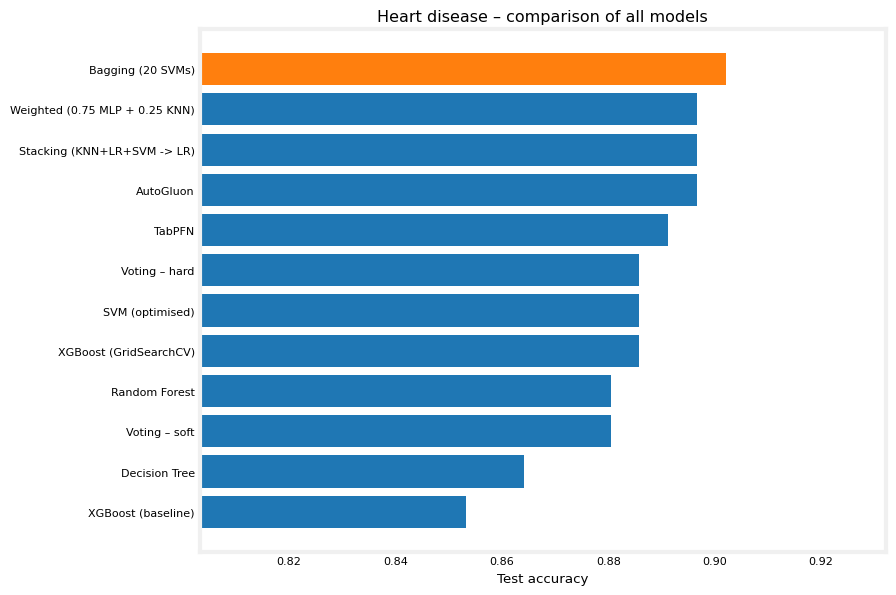

In [37]:
# ---------------- Bagging ensemble with optimised SVMs (20 base learners) ----------------
from sklearn.ensemble import BaggingClassifier

# Optimised individual SVM (RBF) – re-use the GridSearchCV from the stacking activity
svm_opt = grid_svm.best_estimator_
print(f"Optimised SVM params: {grid_svm.best_params_} | CV acc: {grid_svm.best_score_:.4f}")
acc_svm = accuracy_score(y_test, svm_opt.predict(X_test))

bagging_svm = BaggingClassifier(
    estimator=svm_opt,          # each base learner = scaler + SVC with the optimised C and gamma
    n_estimators=20,
    max_samples=1.0,            # bootstrap samples of the same size as the training set
    bootstrap=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
).fit(X_train, y_train)
acc_bagging = accuracy_score(y_test, bagging_svm.predict(X_test))

cv_svm = cross_val_score(svm_opt, X_train, y_train, cv=cv5, n_jobs=-1)
cv_bag = cross_val_score(bagging_svm, X_train, y_train, cv=cv5, n_jobs=-1)
print(f"Optimised SVM      – test acc: {acc_svm:.4f} | CV acc: {cv_svm.mean():.4f} ± {cv_svm.std():.4f}")
print(f"Bagging (20 SVMs)  – test acc: {acc_bagging:.4f} | CV acc: {cv_bag.mean():.4f} ± {cv_bag.std():.4f}")

# Global comparison of every model built in this notebook (test accuracy)
all_models = {
    'Decision Tree': accuracy_score(y_test, decision_tree_model.predict(X_test)),
    'Random Forest': accuracy_score(y_test, random_forest_model.predict(X_test)),
    'XGBoost (baseline)': acc_xgb_base,
    'XGBoost (GridSearchCV)': acc_xgb_tuned,
    'Stacking (KNN+LR+SVM -> LR)': acc_stack,
    'Weighted (0.75 MLP + 0.25 KNN)': acc_weighted,
    'Voting – hard': acc_vote_hard,
    'Voting – soft': acc_vote_soft,
    'SVM (optimised)': acc_svm,
    'Bagging (20 SVMs)': acc_bagging,
}
if 'acc_autogluon' in globals(): all_models['AutoGluon'] = acc_autogluon
if 'acc_tabpfn' in globals():    all_models['TabPFN'] = acc_tabpfn
summary_all = pd.Series(all_models, name='test accuracy').sort_values(ascending=False)
display(summary_all.round(4).to_frame())

plt.figure(figsize=(9, 6))
plt.barh(summary_all.index[::-1], summary_all.values[::-1],
         color=['tab:orange' if 'Bagging' in n else 'tab:blue' for n in summary_all.index[::-1]])
plt.xlim(summary_all.min() - 0.05, min(1, summary_all.max() + 0.03))
plt.xlabel('Test accuracy'); plt.title('Heart disease – comparison of all models')
plt.tight_layout(); plt.show()

**Discussion.** Bagging trains 20 copies of the optimised SVM on bootstrap samples and aggregates their votes. Bagging mainly **reduces variance**, so it helps most with unstable, low-bias learners (deep trees). An RBF SVM with tuned `C` and `gamma` is already a fairly **stable** learner (its decision boundary depends only on the support vectors and is regularised by `C`), and each bootstrap sample contains only ≈ 63 % of the distinct training points, which slightly increases the bias of each SVM. As a result, the bagged SVM performs about the same as the single optimised SVM (see the test and CV accuracies above): the gain, if any, is small, while training/prediction cost is 20× higher. Compared with the other ensembles, the summary table shows that all the well-tuned models (Random Forest, tuned XGBoost, stacking, soft voting, weighted ensemble, AutoGluon, TabPFN) lie within a few points of each other; on a 184-patient test set these differences correspond to just a few patients, so the choice between them should weigh CV performance, cost and interpretability rather than the test accuracy alone.